In [76]:
import numpy as np
import matplotlib.pyplot as plt

from Solver1D import *


mu = 10.00, c = 2.28998


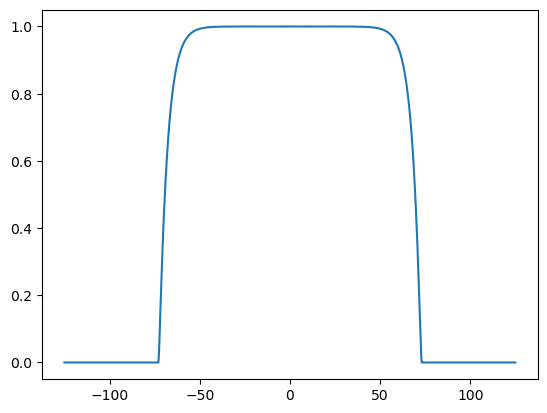

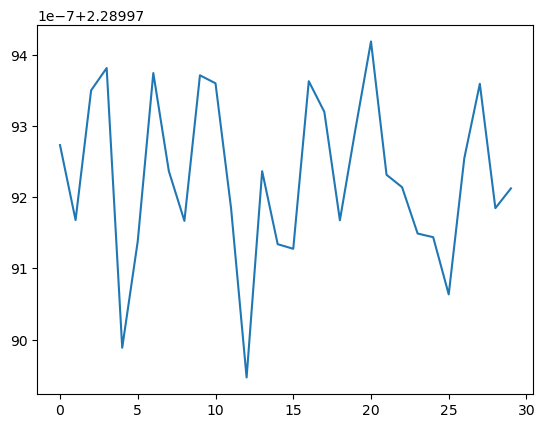

mu = 9.60, c = 2.24619


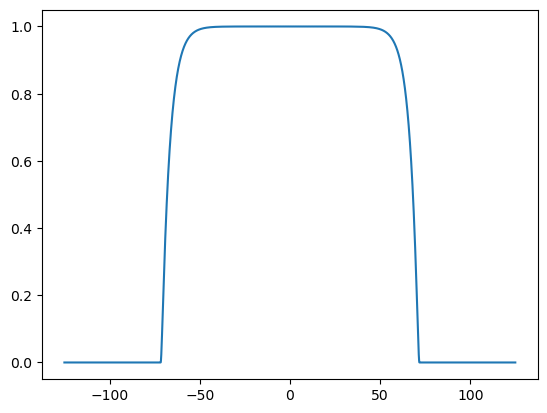

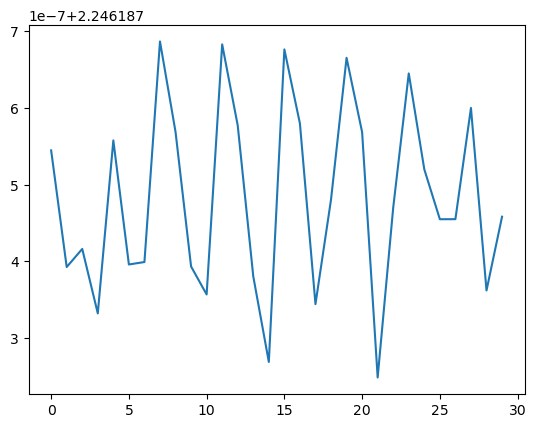

mu = 9.21, c = 2.20155


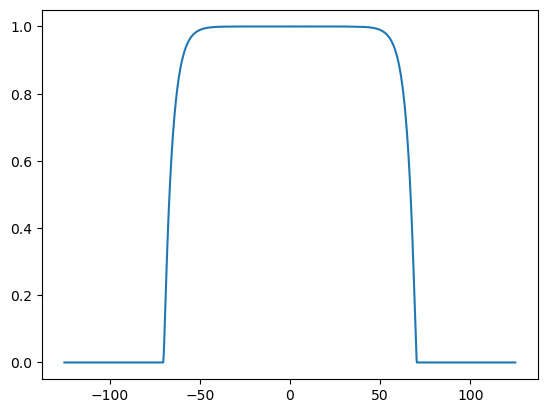

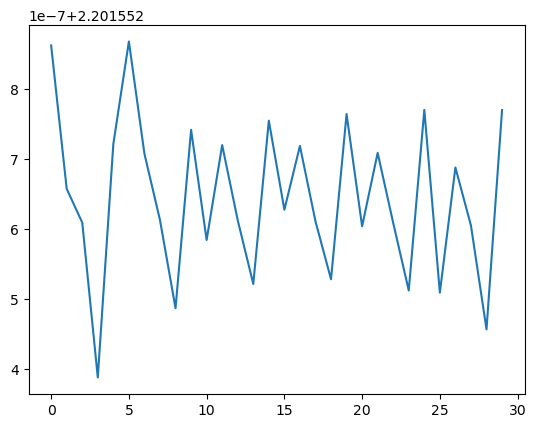

mu = 8.81, c = 2.15603


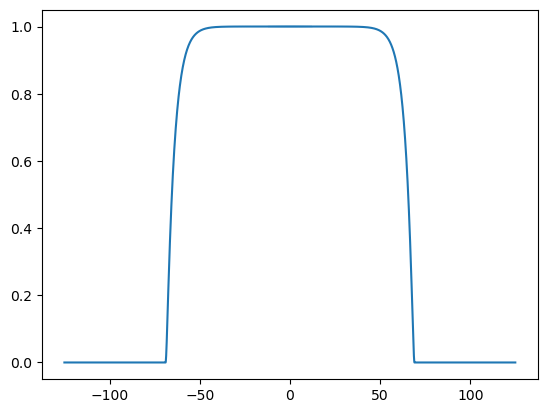

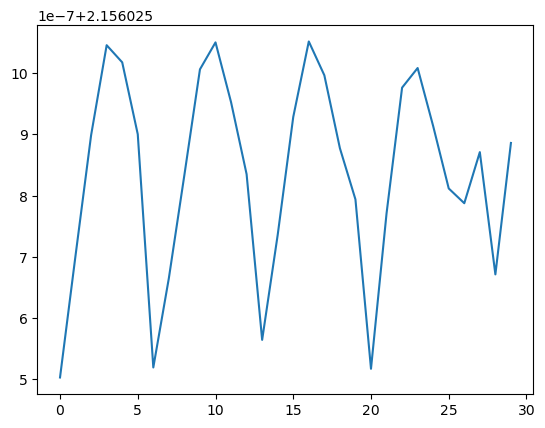

mu = 8.41, c = 2.10955


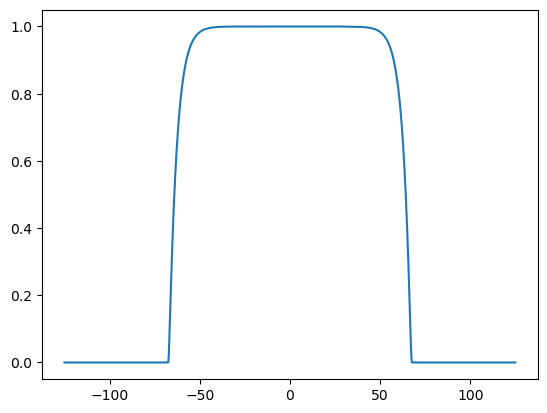

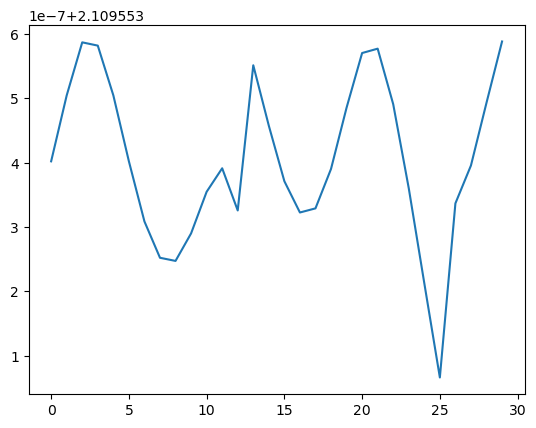

mu = 8.02, c = 2.06208


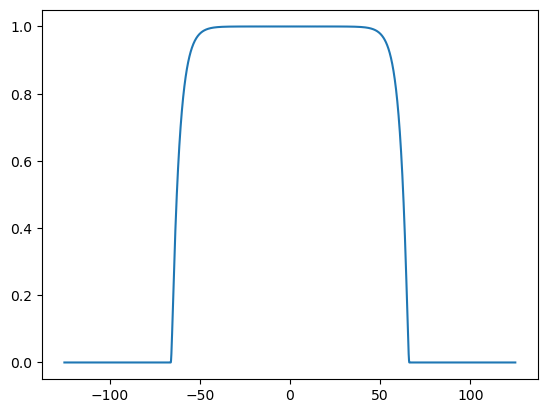

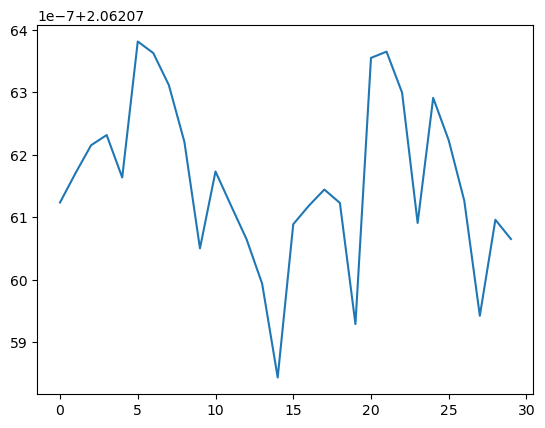

mu = 7.62, c = 2.01353


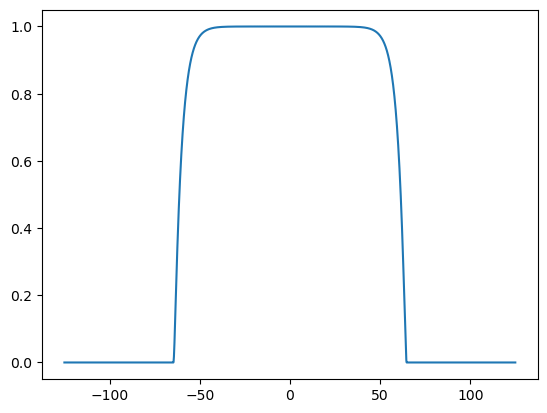

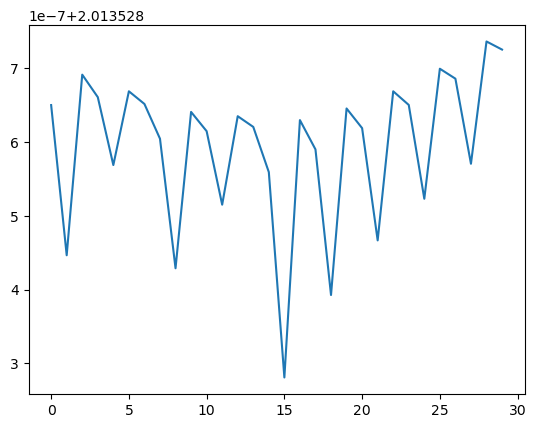

mu = 7.22, c = 1.96384


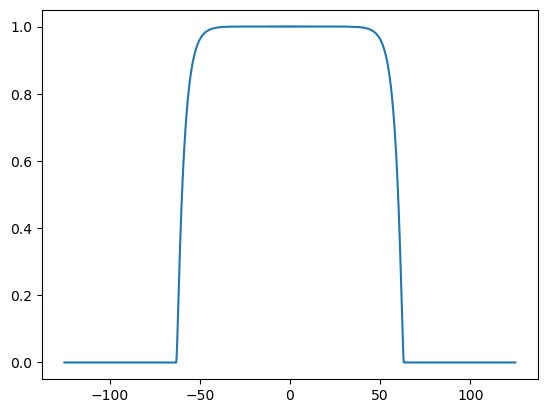

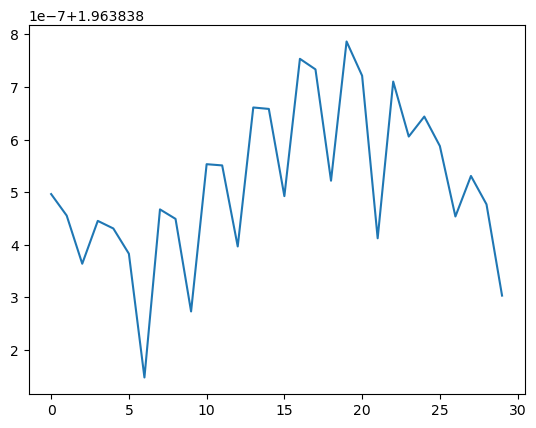

mu = 6.83, c = 1.91292


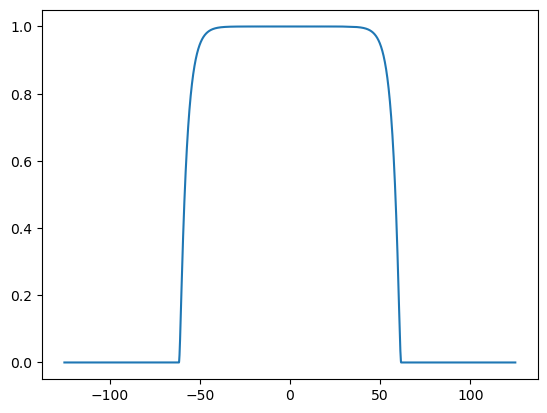

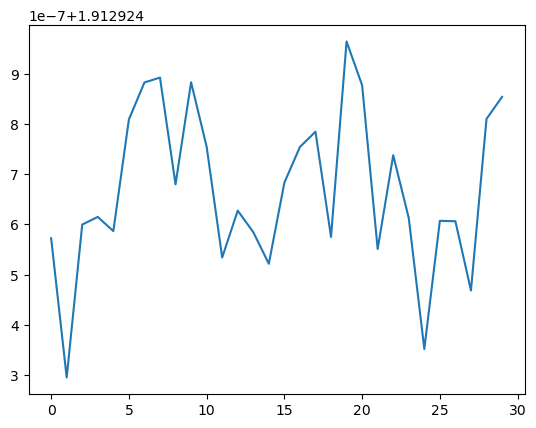

mu = 6.43, c = 1.86070


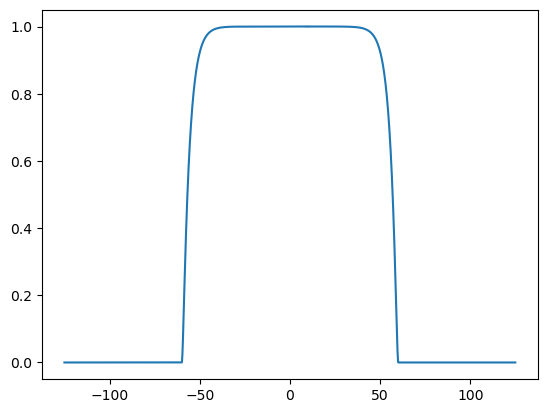

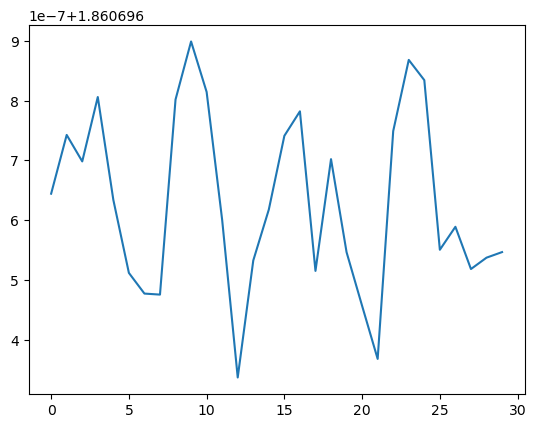

mu = 6.03, c = 1.80705


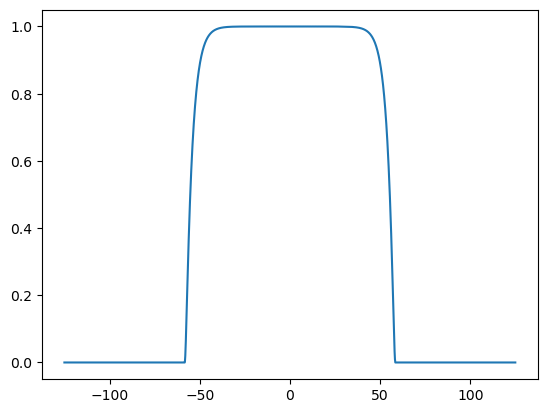

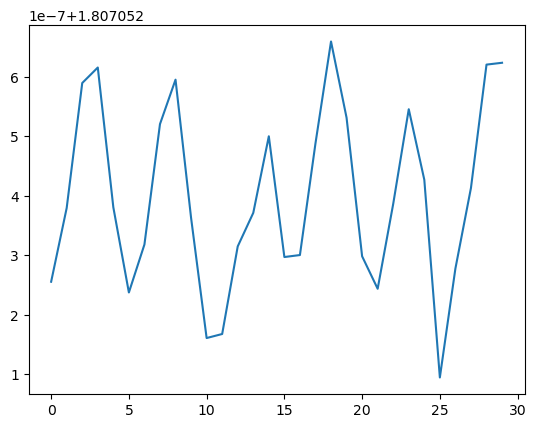

mu = 5.64, c = 1.75188


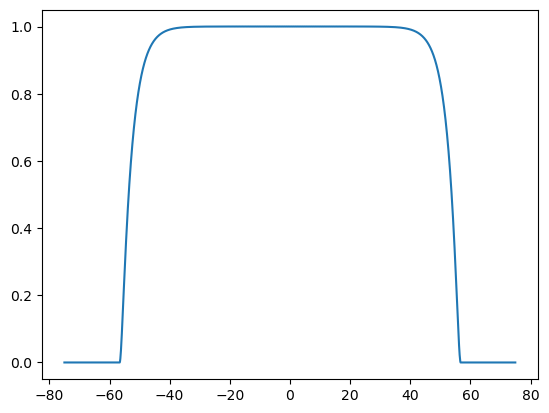

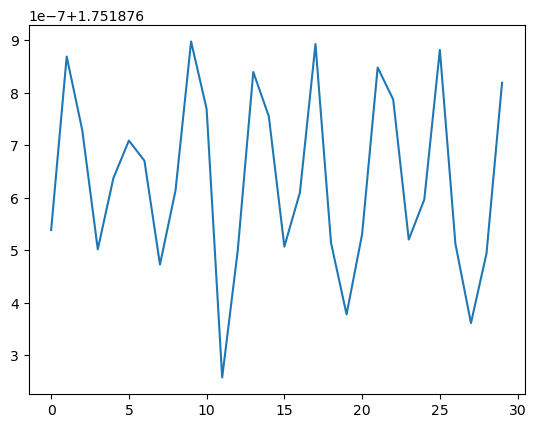

mu = 5.24, c = 1.69504


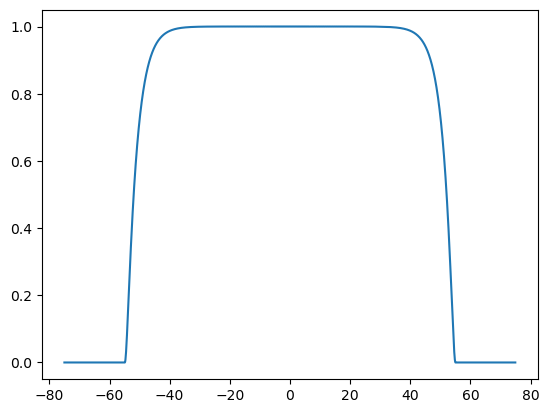

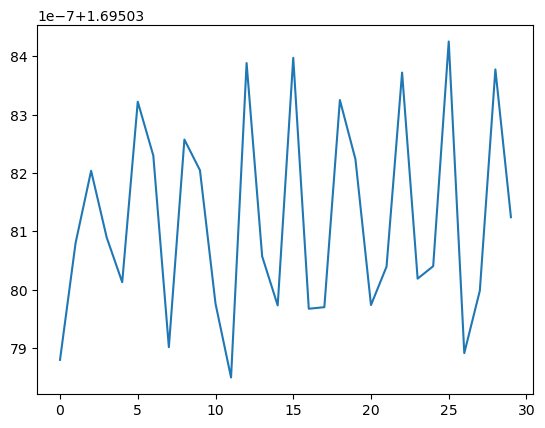

mu = 4.84, c = 1.63639


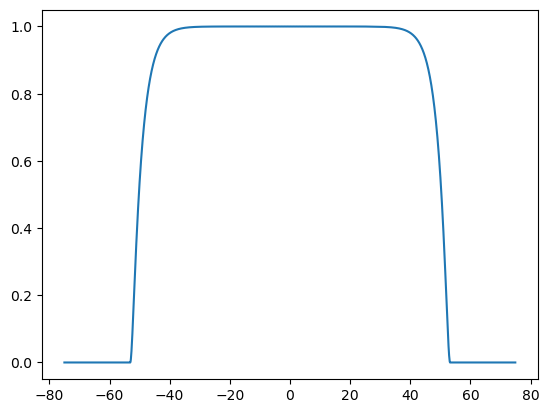

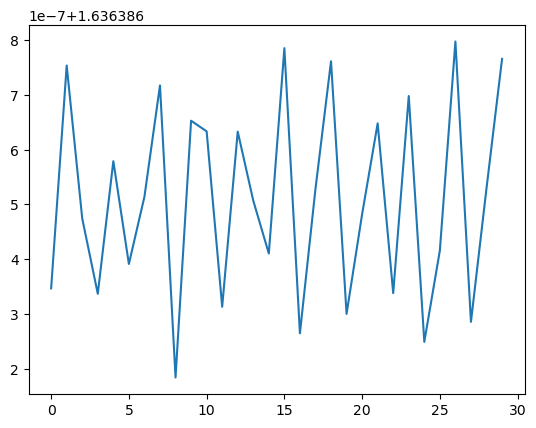

mu = 4.45, c = 1.57575


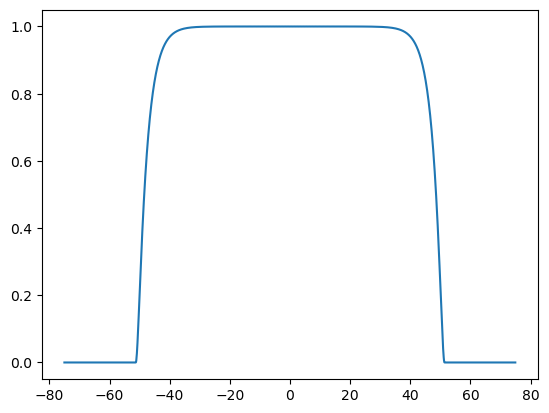

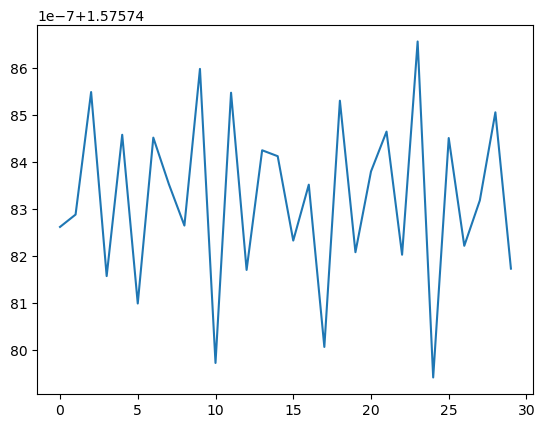

mu = 4.05, c = 1.51292


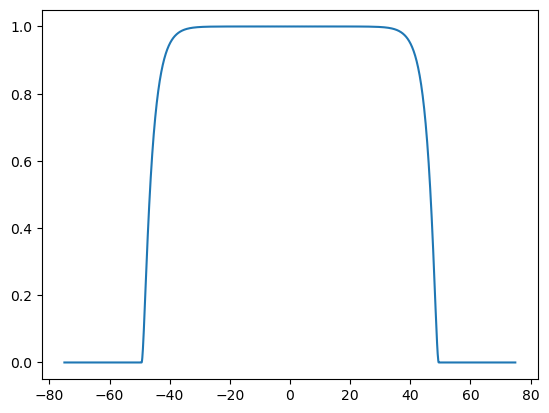

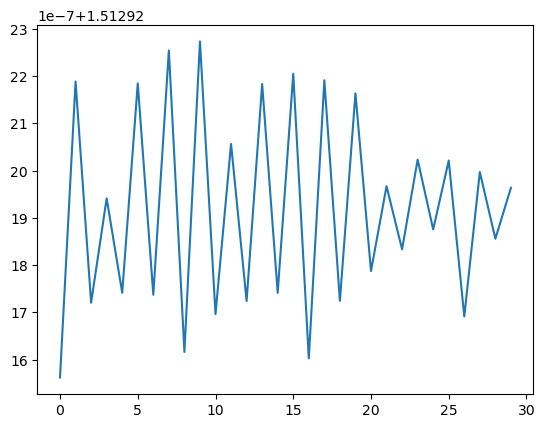

mu = 3.66, c = 1.44767


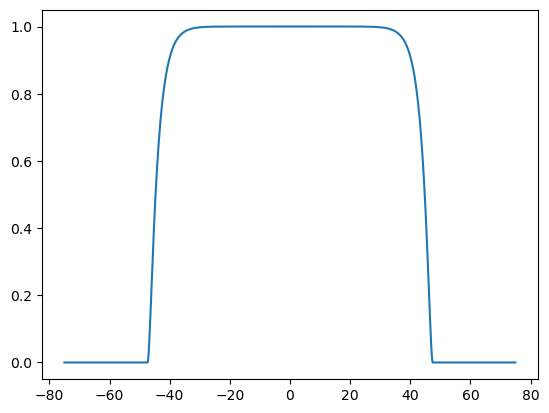

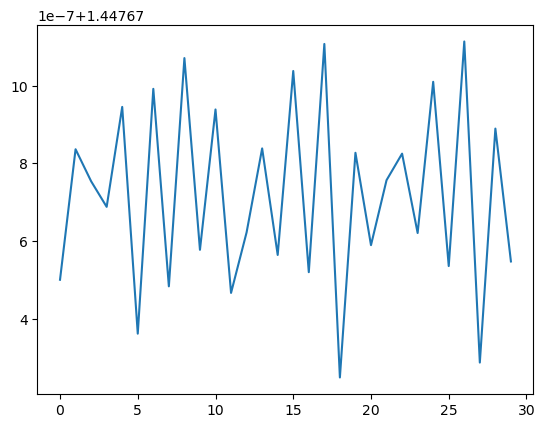

mu = 3.26, c = 1.37971


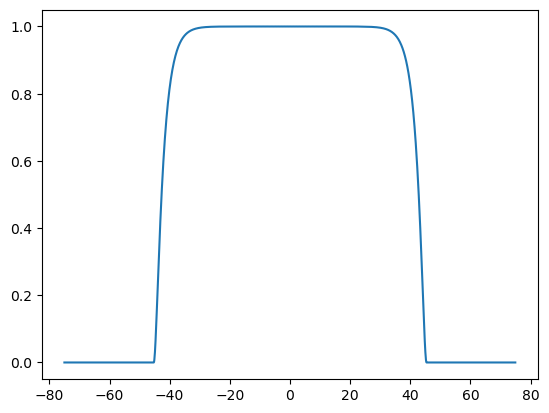

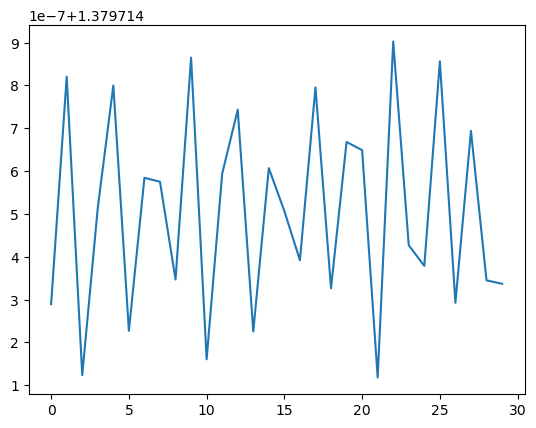

mu = 2.86, c = 1.30872


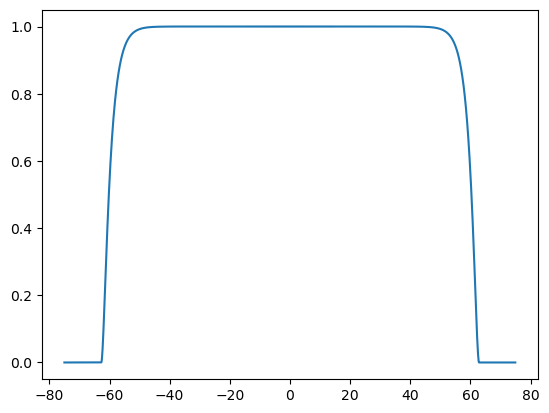

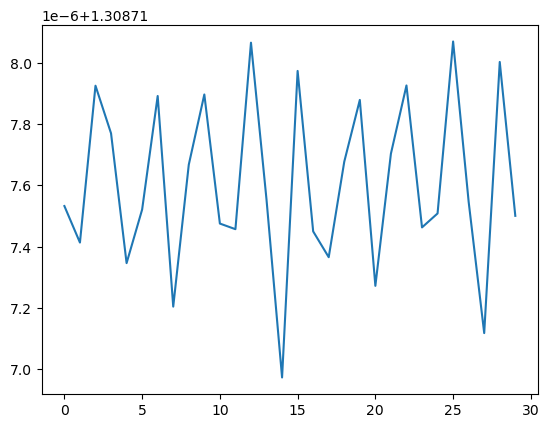

mu = 2.47, c = 1.23427


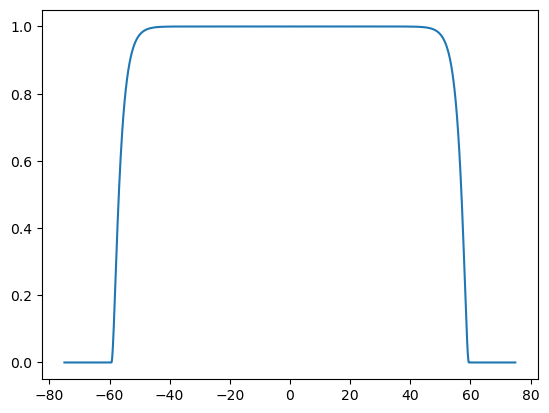

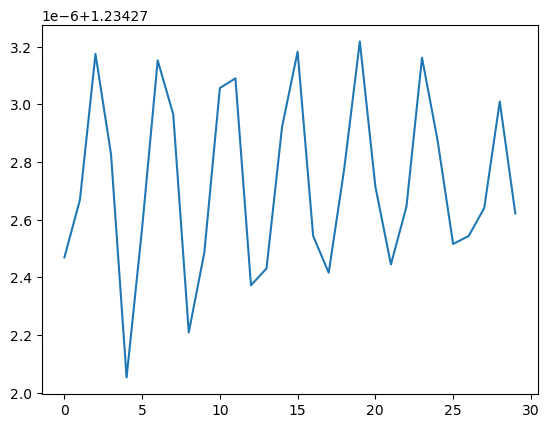

mu = 2.07, c = 1.15588


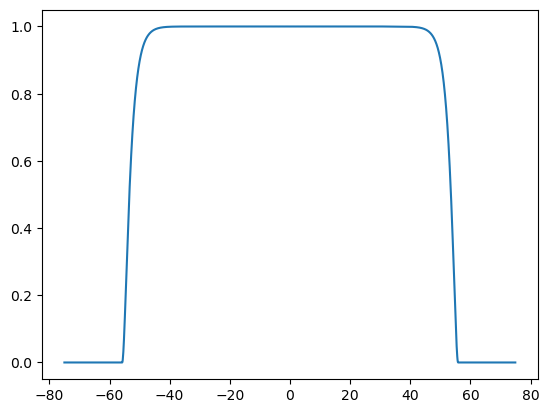

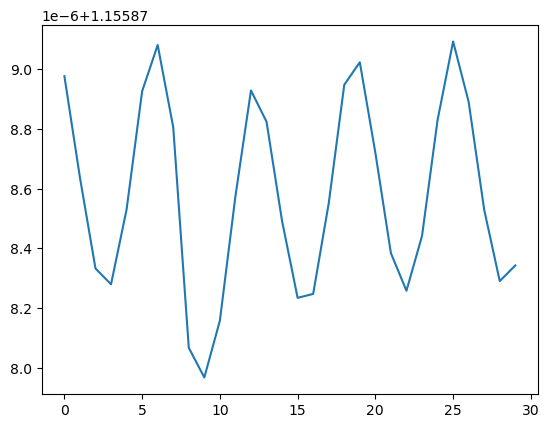

mu = 1.67, c = 1.07291


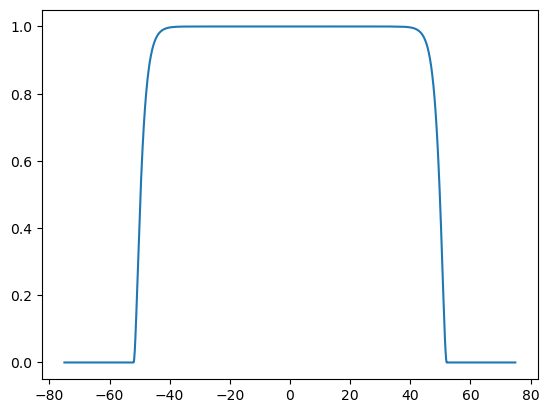

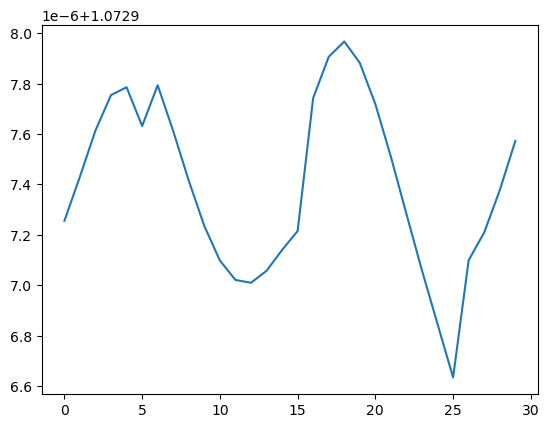

mu = 1.28, c = 0.98456


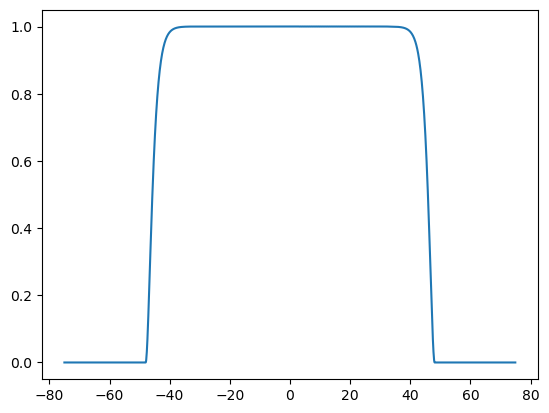

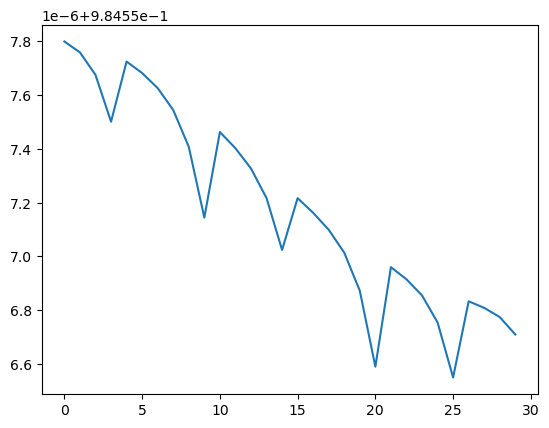

mu = 0.88, c = 0.88978


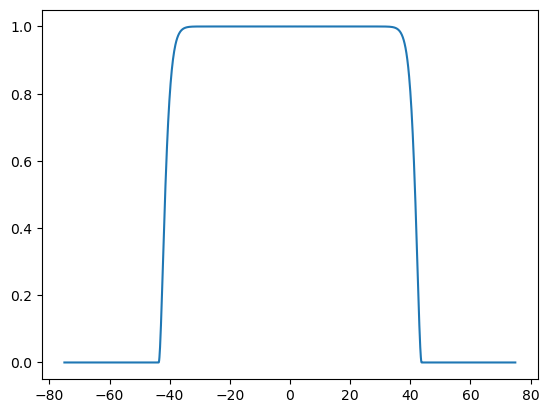

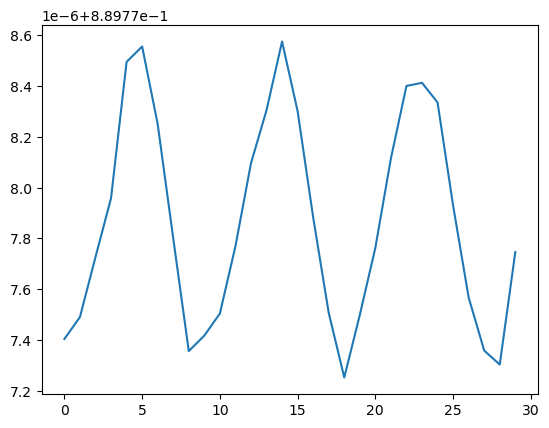

mu = 0.48, c = 0.78715


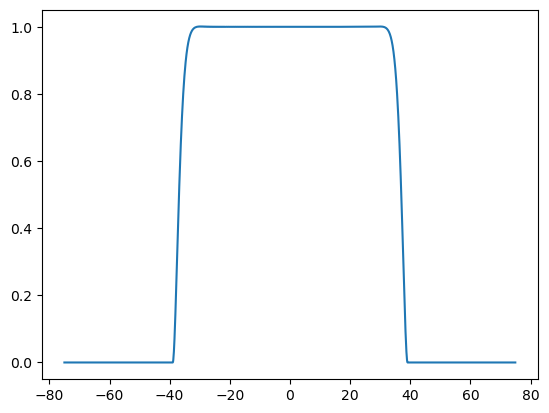

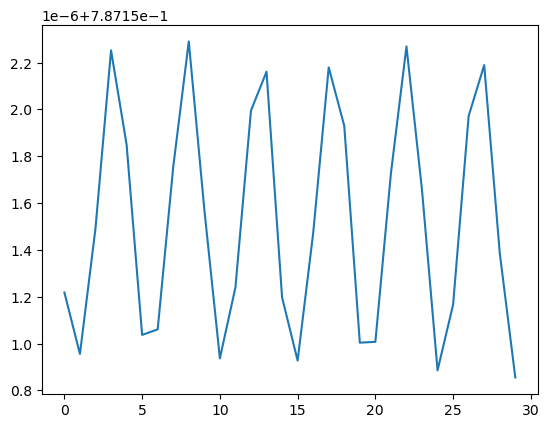

mu = 0.09, c = 0.67471


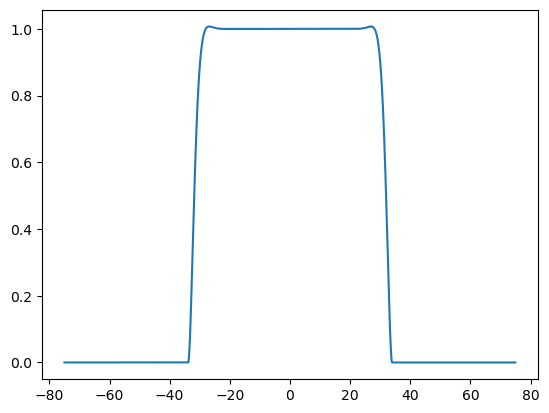

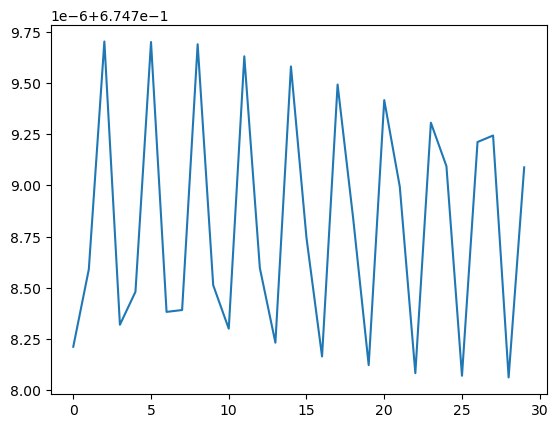

mu = -0.31, c = 0.00000


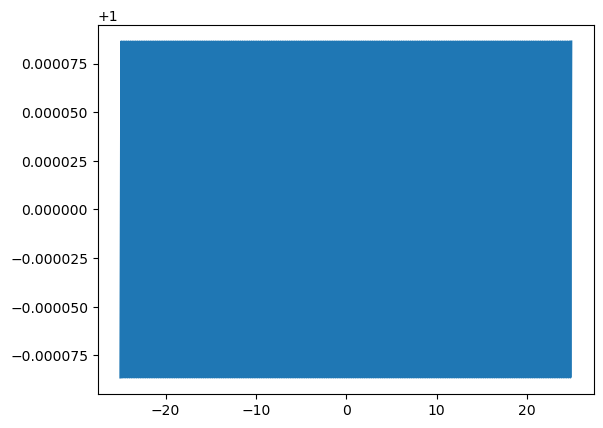

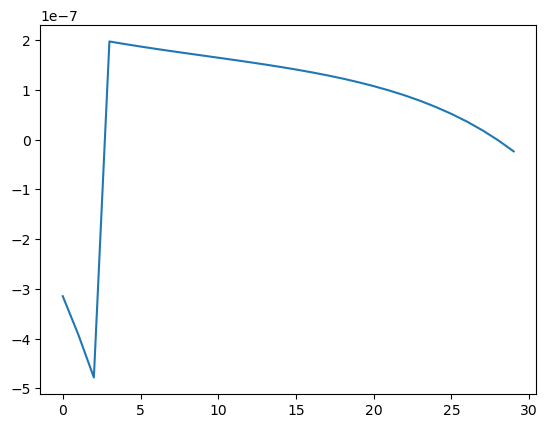

mu = -0.71, c = 0.00047


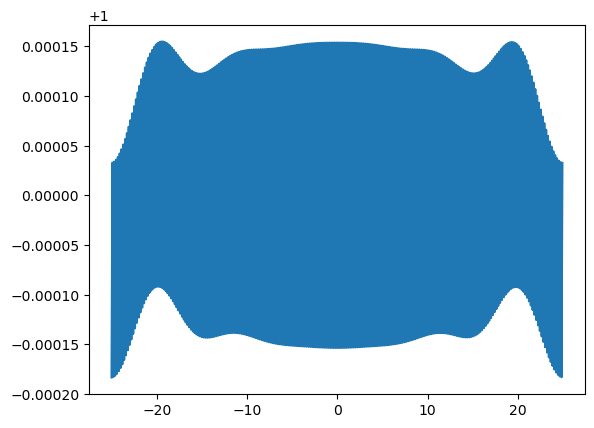

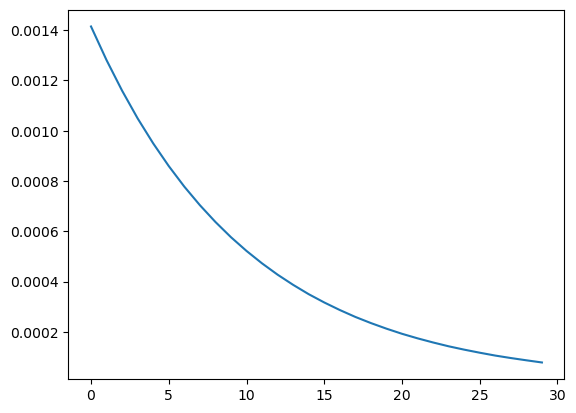

mu = -1.10, c = 0.00000


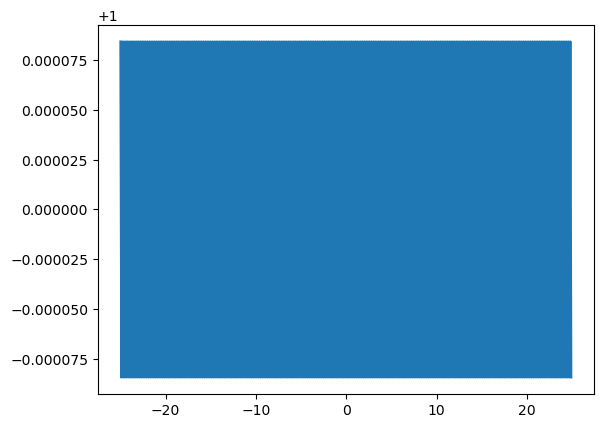

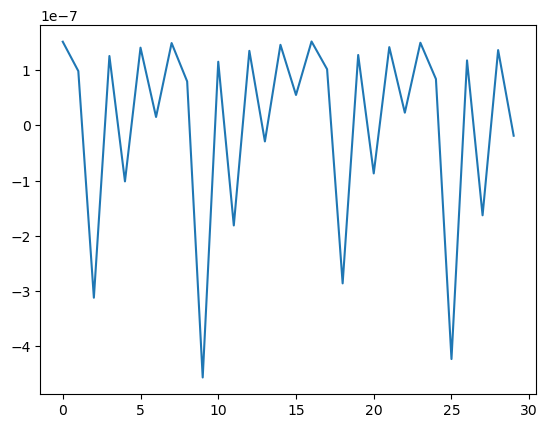

mu = -1.50, c = 0.07069


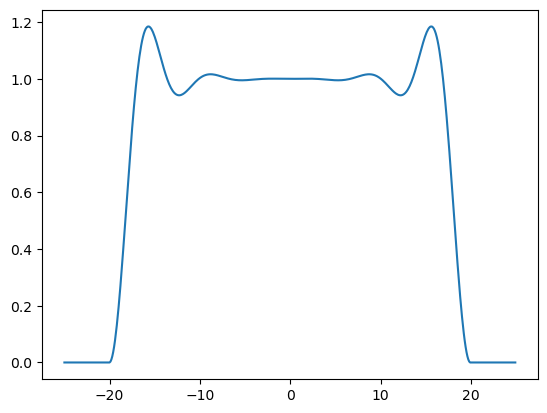

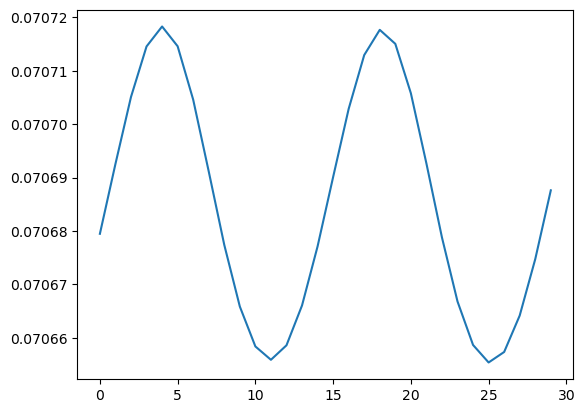

In [89]:
# Figure 3B

mu_values = np.linspace(-1.5, 6, 30)
dx, dt = 0.1, 1e-5
c_values, speeds = [], []

for mu in np.flip(mu_values):
    L = 150 if mu > 0 else 50
    tmax = 150 if mu < -1.3 else 120 if mu < -1 else 50 if mu < 0 else 45 if mu < 3 else 30

    x = np.arange(-L/2, L/2, dx)
    rho0 = (np.abs(x) < (2 if mu > 0 else 8)).astype(float)

    t, rhos = splitting_solver(rho0, mu, tmax, dt, dx, model='I', proliferation=True)

    speed = 0.5 * dx * np.sum(rhos[-30:] * (1 - rhos[-30:]), axis=1)
    speeds.append(speed)
    c_values.append(speed.mean())

    print(f"mu = {mu:.2f}, c = {c_values[-1]:.5f}")

    plt.plot(x, rhos[-1])
    plt.show()
    plt.plot(speed)
    plt.show()

c_values = np.array(c_values)


In [ ]:
data = np.array([mu_values, c_values])
np.save('data_cmu1d.npy', data)

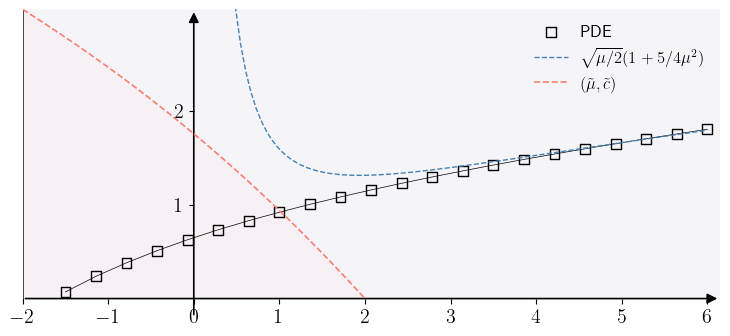

In [139]:
from matplotlib import rcParams

params = {'legend.fontsize': 'large',
         'axes.labelsize': 'x-large',
         'axes.titlesize':'x-large',
         'xtick.labelsize':'x-large',

         'ytick.labelsize':'x-large',
         'font.family': 'sans-serif',
         'text.usetex': True}
rcParams.update(params)
from matplotlib.path import Path
from matplotlib.patches import PathPatch



muspan, cspan = np.load('data_cmu1d.npy')


mupos = np.linspace(1e-6,6,100)
alphaplot = .7


    
fig, ax = plt.subplots(figsize = (9,4))

# Parametric curve Gamma: mu(s), c(s)
s_min = 1/np.sqrt(3)
s_max = 1.0
s = np.linspace(s_min, s_max, 400)
mu = 3*s**2 - 1/s**2   # x-coordinate
c  = -2*s**3 + 2/s     # y-coordinate (c is y)

# Plot limits (adjust if you want)
xpad = 1.0
ypad = 0.4
x_min_plot = -4
x_max_plot = -2
y_min_plot = 0
y_max_plot = 5 + ypad

# Pastel colors (hex)
pastel_yellow = "#F2F2F7"  # light yellow
pastel_red    = "#E3E7F1"  # light pastel red / pink
pastel_blue   = "#F5EBF0"  # light pastel blue

ax.axvspan(x_min_plot, -4.0, ymin=0.07, ymax=1, facecolor=pastel_yellow, alpha=alphaplot, zorder=0)


y_grid = np.linspace(0.0, c.max(), 400)

idx_sort = np.argsort(c)  # sorts c in increasing order
c_sorted = c[idx_sort]
mu_sorted = mu[idx_sort]
mu_at_y = np.interp(y_grid, c_sorted, mu_sorted)
# Now fill between x=mu_at_y and x_max_plot for y_grid
ax.fill_betweenx(y_grid , mu_at_y, x_max_plot, facecolor=pastel_blue, alpha=alphaplot, zorder=0)

# Also plot the horizontal y=0 line from x=-2 to x_max_plot for clarity (thin black)
ax.plot([x_min_plot, x_max_plot], [0,0], color='black', lw=0.8, zorder=2)


# Remove all spines (the box around the plot)
for spine in ax.spines.values():
    spine.set_visible(False)

# Move ticks to bottom and left only
ax.xaxis.set_ticks_position('bottom')
ax.yaxis.set_ticks_position('left')

# Set tick positions to cross at (0,0)
ax.spines['bottom'].set_position('zero')
ax.spines['left'].set_position('zero')

ax.set_xlim(-2, 6.15)
ax.set_ylim(-.2, 16*np.sqrt(3)/9)

xmin, xmax = ax.get_xlim()
ymin, ymax = ax.get_ylim()

ax.annotate(
    "", xy=(xmax, 0), xytext=(xmin, 0),
    arrowprops=dict(arrowstyle="-|>", color='black', linewidth=1.2, mutation_scale=15)
)

ax.annotate(
    "", xy=(0, ymax), xytext=(0, ymin),
    arrowprops=dict(arrowstyle="-|>", color='black', linewidth=1.2, mutation_scale=15)
)

ax.scatter(muspan, cspan, edgecolor = 'black', color = 'none', marker = 's', label = 'PDE', s = 50)
ax.plot(muspan, cspan, color = 'black', lw = .5)
#ax.plot(mupos, np.sqrt(mupos/2), color = 'dodgerblue', linestyle = '-', lw = 1, label = '$\sqrt{\mu/2}$')
ax.plot(mupos, np.sqrt(mupos/2)*(1+5/mupos**2/4), color = 'steelblue', linestyle = '--', lw = 1, label = '$\\sqrt{\\mu/2}(1 + 5/4\\mu^2)$')
ax.plot([-2,-2],[0,4], color = 'black', lw = .5)

ax.plot(mu, c, color="salmon", lw=1.2, zorder=3, label='$(\\tilde\\mu ,\\tilde c)$', linestyle = '--')


ax.set_xticks([-2,-1,0,1,2,3,4,5,6])
ax.set_yticks([1,2])

mu_right = ax.get_xlim()[1]
c_top = ax.get_ylim()[1]

shade = dict(
    facecolor=pastel_yellow,
    edgecolor="none",
    alpha=alphaplot,
    zorder=0,
)

ax.fill_between(mu, np.maximum(c, 0.0), c_top, **shade)

if mu_right > 2.0:
    ax.fill_between([2.0, mu_right], 0.0, c_top, **shade)


    
ax.legend(frameon = False)

plt.savefig('constant-adhesion-model-speed.pdf', dpi = 1200,  transparent = True)
plt.show()